In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy
from matplotlib.ticker import FuncFormatter

from shared import (
    BARD_RATE,
    mixture_distribution,
    pmf_std,
    relative_d2,
    thousands_formatter,
    set_custom_style,
)

# Set custom plot style
set_custom_style()

['#5842ff', '#ff4000', '#00b368']

In [2]:
def p_apex_arrow(n_song_ticks, n_ea):
    r_support = np.arange(0, n_song_ticks + 1)
    sg_support = np.arange(75, 105, 5)

    r_pmf = scipy.stats.binom.pmf(r_support, n_song_ticks, 0.8)
    sg_pmf = np.zeros(shape=sg_support.shape)

    sg_pmf[0] = r_pmf[0 : 15 - n_ea + 1].sum()
    sg_pmf[1:] = r_pmf[15 - n_ea + 1 : 20 - n_ea + 1]
    sg_pmf[-1] = r_pmf[20 - n_ea :].sum()

    return sg_pmf, sg_support

In [3]:
def p_apex_arrow2(k_sg, n_song_ticks, n_ea):
    r_support = np.arange(0, n_song_ticks + 1)

    r_pmf = scipy.stats.binom.pmf(r_support, n_song_ticks, 0.8)
    sg_pmf = np.zeros(shape=(6,))

    sg_pmf[0] = r_pmf[0 : 15 - n_ea + 1].sum()
    sg_pmf[1:] = r_pmf[15 - n_ea + 1 : 20 - n_ea + 1]
    sg_pmf[-1] = r_pmf[20 - n_ea :].sum()

    return sg_pmf[k_sg // 5 - 15]

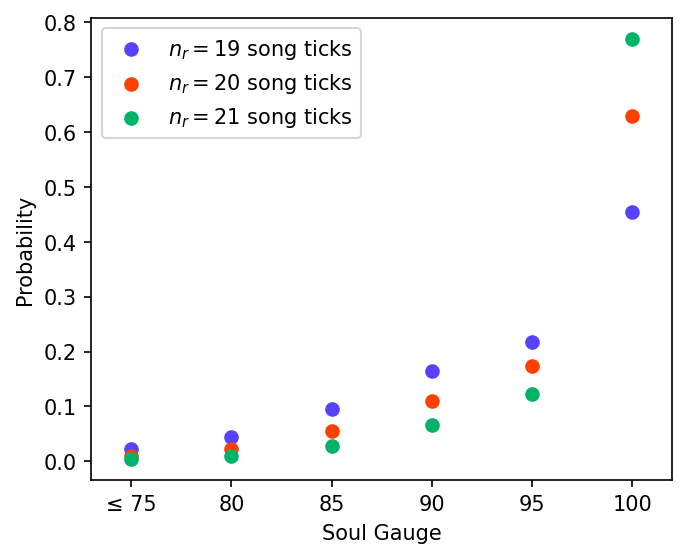

In [4]:
n1 = 19
n2 = 20
n3 = 21
pmf, gauge = p_apex_arrow(n1, 4)
pmf2, gauge2 = p_apex_arrow(n2, 4)
pmf3, gauge3 = p_apex_arrow(n3, 4)

fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=150)
ax.scatter(gauge, pmf, label=rf"$n_r = {n1}$ song ticks")
ax.scatter(gauge2, pmf2, label=rf"$n_r = {n2}$ song ticks")
ax.scatter(gauge3, pmf3, label=rf"$n_r = {n3}$ song ticks")
ax.set_xlim([73, 102])
ax.set_xticks([75, 80, 85, 90, 95, 100])
ax.set_xticklabels(["≤ 75", "80", "85", "90", "95", "100"])
ax.set_xlabel("Soul Gauge")
ax.set_ylabel("Probability")
ax.legend()
plt.savefig("../tex/img/aa-sg-distribution.png")
plt.show()

In [5]:
import pandas as pd

print("Blast Arrow potency:", relative_d2(600))
pd.DataFrame(
    [
        {"Soul Gauge": p // 6, "Potency": p, "D": relative_d2(p)}
        for p in range(480, 630, 30)
    ]
)

Blast Arrow potency: 27272


,Soul Gauge,Potency,D
0,80,480,21818
1,85,510,23181
2,90,540,24545
3,95,570,25909
4,100,600,27272


In [6]:
from ffxiv_stats import Rotation


def make_aa_record(d2, p, multiplier, name_append: str = ""):
    return {
        "n": 1,
        "d2": d2,
        "action_name": f"Apex Arrow-{name_append}",
        "base_action": "Apex Arrow",
        "p_n": p[0],
        "p_c": p[1],
        "p_d": p[2],
        "p_cd": p[3],
        "l_c": BARD_RATE.l_c,
        "buffs": multiplier,
        "is_dot": False,
    }


gauge_to_d2 = {75: 0, 80: 21818, 85: 23181, 90: 14545, 95: 25909, 100: 27272}

rotations = []
w = []
for k_odd in range(75, 105, 5):
    for k_even in range(75, 105, 5):
        d2_even = gauge_to_d2[k_even]
        d2_odd = gauge_to_d2[k_odd]

        records = []
        if k_even > 75:
            records.append(
                make_aa_record(d2_even, BARD_RATE.get_p(0.02, 0.2), 1.219, "burst")
            )

        if k_odd > 75:
            records.append(make_aa_record(d2_odd, BARD_RATE.p, 1.0))

        if len(records) > 0:
            rotation_df = pd.DataFrame(records)
            rotations.append(Rotation(rotation_df, 1, 1, 1, 1, 1))
            w.append(p_apex_arrow2(k_even, 20, 4) * p_apex_arrow2(k_odd, 20, 4))


sigma percent change: 16.1%


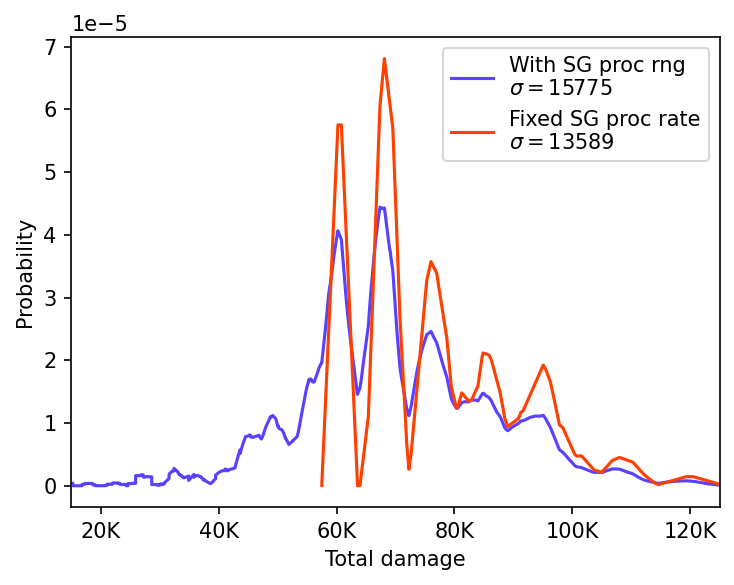

In [7]:
pmf, support = mixture_distribution(rotations, w)

proc_std = pmf_std(support, pmf)
mode_std = rotations[-1].rotation_std

print(f"sigma percent change: {(proc_std - mode_std) / mode_std:.1%}")


fig, ax = plt.subplots(1, 1, figsize=(5, 4), dpi=150)
ax.plot(support, pmf, label="With SG proc rng\n" + rf"$\sigma={proc_std:.0f}$")
rotations[-1].plot_rotation_distribution(
    ax=ax, label="Fixed SG proc rate\n" + rf"$\sigma={mode_std:.0f}$"
)

ax.xaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax.set_ylabel("Probability")
ax.set_xlabel("Total damage")
ax.set_xlim([15000, 125000])
ax.legend()
plt.tight_layout()
plt.savefig("../tex/img/aa-dmg-dist.png")
plt.show()